ASSIGNMENT NO 1

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  


from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv("winequality.csv")
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,white,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,white,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,red,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,red,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6494,red,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
6495,red,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [4]:
df.shape

(6497, 13)

In [5]:
df.columns

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='str')

In [6]:
df.dtypes

type                        str
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [7]:
df.isnull().sum()
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,white,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,white,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,red,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,red,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6494,red,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
6495,red,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [26]:
df = df.dropna().copy()

print(df.isnull().sum())
print(df.shape)

type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
(6463, 13)


In [27]:
y  = df["type"]
X = df.drop(columns=["type"])

In [28]:
X  = X.select_dtypes(include = np.number)
print("\n Original number of features:",X.shape[1])
print("Wine type:",y.unique())


 Original number of features: 12
Wine type: <ArrowStringArray>
['white', 'red']
Length: 2, dtype: str


In [29]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2,stratify=y)

In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) 

In [32]:
model_before = LogisticRegression(max_iter=2000)
model_before.fit(X_train_scaled,y_train)

y_pred_before = model_before.predict(X_test_scaled)
accuracy_before = accuracy_score(y_test,y_pred_before)

print("\n Accuracy before PCA:",round(accuracy_before*100,2),"%")


 Accuracy before PCA: 99.61 %


In [35]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("\nReduced number of features: ", X_train_pca.shape[1])
print("\nExplained Variance ratio:",pca.explained_variance_ratio_)
print("Total variance retained:",round(pca.explained_variance_ratio_.sum()*100,2),"%")


Reduced number of features:  2

Explained Variance ratio: [0.25406597 0.22113652]
Total variance retained: 47.52 %


In [37]:
model_after = LogisticRegression(max_iter=2000)
model_after.fit(X_train_pca,y_train)

y_pred_after = model_after.predict(X_test_pca)
accuracy_after = accuracy_score(y_test,y_pred_after)

print("Accuracy After PCA: ",round(accuracy_after*100,2),"%")

Accuracy After PCA:  98.3 %


In [40]:
print("\nAccuracy Comparison")
print(f"Before PCA: {accuracy_before*100:.2f}%")
print(f"After PCA: {accuracy_after*100:.2f}%")
print(f"Difference: {(accuracy_after-accuracy_before)*100:.2f}percentage points")


Accuracy Comparison
Before PCA: 99.61%
After PCA: 98.30%
Difference: -1.31percentage points


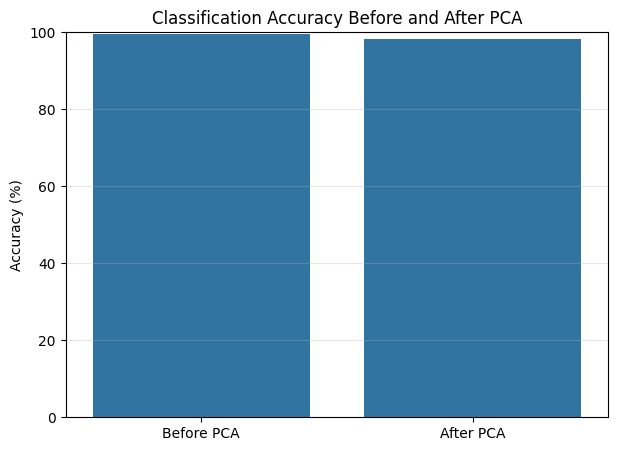

In [42]:
plt.figure(figsize=(7,5))

sns.barplot(
    x = ["Before PCA","After PCA"],
    y = [accuracy_before*100,accuracy_after*100]
)

plt .ylabel("Accuracy (%)")
plt.title("Classification Accuracy Before and After PCA")
plt.ylim(0,100)
plt.grid(axis="y",alpha=0.3)
plt.show()

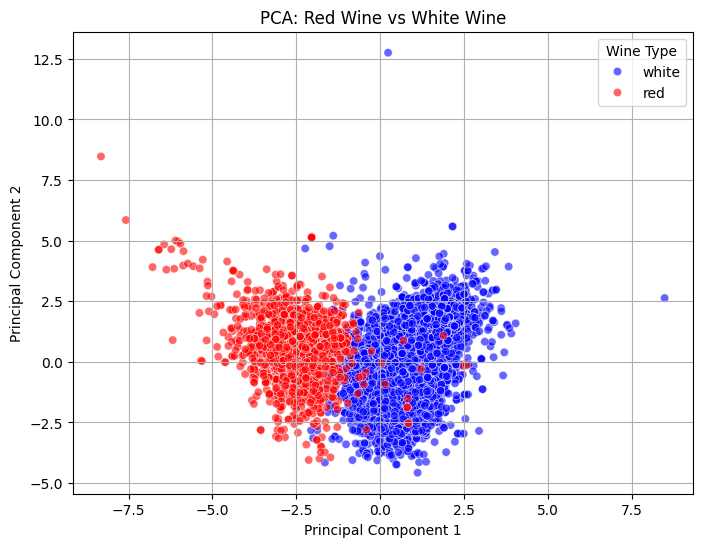

In [45]:
X_pca = pca.transform(scaler.transform(X))

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["type"] = y.reset_index(drop=True)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="type",
    palette={"red": "red", "white": "blue"},
    alpha=0.6
)

plt.title("PCA: Red Wine vs White Wine")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Wine Type")
plt.grid(True)
plt.show()

ASSIGNMENT NO 2

In [38]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso,LinearRegression,Ridge

In [39]:
df = pd.read_csv("bike(hour).csv")
df

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


In [40]:
df.shape

(17379, 17)

In [41]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [42]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

In [44]:
X = df[['instant', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered']]
y = df['cnt']

In [45]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

In [46]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [47]:
lr = LinearRegression()

lr.fit(X_train_scaled,y_train)
lr_pred = lr.predict(X_test_scaled)

In [48]:
rg = Ridge()

rg.fit(X_test_scaled,y_test)
rg_pred = rg.predict(X_test_scaled)

In [49]:
ls = Lasso()

ls.fit(X_test_scaled, y_test)
ls_pred = ls.predict(X_test_scaled)

In [50]:
print("\n*****Linear Regression*****")
print("R2 Score :", r2_score(y_test,lr_pred))
print("MSE      :",mean_squared_error(y_test,lr_pred))
print("\n*****Ridge Regression*****")
print("R2 Score :",r2_score(y_test,rg_pred))
print("MSE      :",mean_squared_error(y_test,rg_pred))
print("\n*****Lasso Regression*****")
print("R2 Score :",r2_score(y_test,ls_pred))
print("MSE      :",mean_squared_error(y_test,ls_pred))


*****Linear Regression*****
R2 Score : 1.0
MSE      : 2.693254283081517e-25

*****Ridge Regression*****
R2 Score : 0.9999999049981695
MSE      : 0.0030082720417082707

*****Lasso Regression*****
R2 Score : 0.9999558419199831
MSE      : 1.398283767564707


ASSIGNMENT NO 3

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.tree import DecisionTreeClassifier

In [52]:
df = pd.read_csv("winequality.csv")
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,white,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,white,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,red,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,red,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6494,red,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
6495,red,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [53]:
df.isnull().sum()


type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64

In [54]:
df.dropna(inplace=True)

In [55]:
df.isnull().sum()

type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [56]:
df.shape

(6463, 13)

In [57]:
df.columns

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='str')

In [71]:
x = df.drop(["type","quality"],axis=1)
y = df["quality"]

In [72]:
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=42,test_size=0.2)

In [73]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [74]:
lg = LogisticRegression(max_iter=500)

lg.fit(x_train_scaled,y_train)
lg_pred = lg.predict(x_test_scaled)
print(lg_pred)

[6 5 6 ... 6 5 5]


In [75]:
lg_accu = accuracy_score(y_test,lg_pred)
print("Accuracy :",lg_accu*100)

Accuracy : 53.596287703016245


In [76]:
cr = classification_report(y_test,lg_pred)
print("Classification Report : \n",cr)

Classification Report : 
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.50      0.02      0.04        48
           5       0.61      0.57      0.59       430
           6       0.50      0.71      0.59       540
           7       0.51      0.27      0.35       228
           8       0.00      0.00      0.00        42
           9       0.00      0.00      0.00         1

    accuracy                           0.54      1293
   macro avg       0.30      0.22      0.22      1293
weighted avg       0.52      0.54      0.51      1293



C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [77]:
ln = LinearRegression()

ln.fit(x_train_scaled,y_train)
ln_pred = ln.predict(x_test_scaled)
print("Prediction: ",ln_pred)

Prediction:  [5.77060569 5.59227    6.3505669  ... 6.06408718 5.48409561 5.27417149]


In [79]:
ln_pred_class = ln_pred.round().astype(int)
ln_pred_class = ln_pred_class.clip(y_test.min(), y_test.max())
ln_acc = accuracy_score(y_test, ln_pred_class)
print("Accuracy : ", ln_acc)

Accuracy :  0.5290023201856149


In [80]:
cr1 = classification_report(y_test,ln_pred_class)
print("Classification Report :\n",cr)

Classification Report :
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.50      0.02      0.04        48
           5       0.61      0.57      0.59       430
           6       0.50      0.71      0.59       540
           7       0.51      0.27      0.35       228
           8       0.00      0.00      0.00        42
           9       0.00      0.00      0.00         1

    accuracy                           0.54      1293
   macro avg       0.30      0.22      0.22      1293
weighted avg       0.52      0.54      0.51      1293



C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [82]:
dt = DecisionTreeClassifier(random_state=42,max_depth=15)
dt.fit(x_train_scaled,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n

In [84]:
dt_pred = dt.predict(x_test_scaled)
print(dt_pred)

[5 6 7 ... 8 6 5]


In [88]:
dt_acc = accuracy_score(y_test,dt_pred)
print("Accuracy :",dt_acc*100)

Accuracy : 55.83913379737046


In [90]:
cr = classification_report(y_test,dt_pred)
print("Classification Report :",cr)

Classification Report :               precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.13      0.06      0.08        48
           5       0.61      0.67      0.64       430
           6       0.57      0.57      0.57       540
           7       0.49      0.49      0.49       228
           8       0.39      0.29      0.33        42
           9       0.00      0.00      0.00         1

    accuracy                           0.56      1293
   macro avg       0.31      0.30      0.30      1293
weighted avg       0.55      0.56      0.55      1293



C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

ASSIGNMENT NO 4

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report

In [2]:
df = pd.read_csv("Breast_cancer.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
print("\nMissing Values:")
df.isnull().sum()


Missing Values:


id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [4]:
df.drop(columns=["id", "Unnamed: 32"], inplace=True)


df["diagnosis"] = df["diagnosis"].map({"M":1,"B":0})


In [5]:
x = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [6]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2)

In [7]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [8]:
SVM_model = SVC(kernel="rbf",C=1.0,gamma="scale")
SVM_model.fit(x_train_scaled,y_train)
model_pred = SVM_model.predict(x_test_scaled)
print("Prediction : ",model_pred)

Prediction :  [0 1 1 0 0 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1
 0 1 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 1 0 0 1 1 0 0 0 1 1 0 0 1 1 0 1
 0 0 0 0 0 0 1 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 1 1 0 1 1 0 1 1 0 0 0 1 0 0 1
 0 0 1]


In [9]:
print("\nModel Evaluation")
print("------------------------------------")
print("Accuracy :",accuracy_score(y_test,model_pred))
print("Classification report:",classification_report(y_test,model_pred))


Model Evaluation
------------------------------------
Accuracy : 0.9824561403508771
Classification report:               precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



ASSIGNMENT NO 5

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [3]:
df = pd.read_csv("covtype.csv")
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [4]:
print("\nMessing Value:")
df.isnull().sum()


Messing Value:


Elevation                             0
Aspect                                0
Slope                                 0
Horizontal_Distance_To_Hydrology      0
Vertical_Distance_To_Hydrology        0
Horizontal_Distance_To_Roadways       0
Hillshade_9am                         0
Hillshade_Noon                        0
Hillshade_3pm                         0
Horizontal_Distance_To_Fire_Points    0
Wilderness_Area1                      0
Wilderness_Area2                      0
Wilderness_Area3                      0
Wilderness_Area4                      0
Soil_Type1                            0
Soil_Type2                            0
Soil_Type3                            0
Soil_Type4                            0
Soil_Type5                            0
Soil_Type6                            0
Soil_Type7                            0
Soil_Type8                            0
Soil_Type9                            0
Soil_Type10                           0
Soil_Type11                           0


In [5]:
df.shape

(581012, 55)

In [6]:
x = df.drop(columns=["Cover_Type"])
y = df["Cover_Type"]

In [7]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [8]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [9]:
rf = RandomForestClassifier(n_estimators=100,criterion='gini',max_depth=None,random_state=42,n_jobs=-1)

In [10]:
rf.fit(x_train_scaled,y_train)
print("Model trained successfully.")

Model trained successfully.


In [14]:
y_pred = rf.predict(x_test)
Accuracy = accuracy_score(y_test,y_pred)
print("Accuracy :",Accuracy*100 ,"%")
Cl = classification_report(y_test,y_pred)
print("\nClassical Report :\n",Cl)

C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Accuracy : 29.206646988459852 %

Classical Report :
               precision    recall  f1-score   support

           1       0.21      0.00      0.01     42557
           2       0.49      0.55      0.52     56500
           3       0.00      0.00      0.00      7121
           4       0.00      0.00      0.00       526
           5       0.00      0.00      0.00      1995
           6       0.00      0.00      0.00      3489
           7       0.05      0.64      0.09      4015

    accuracy                           0.29    116203
   macro avg       0.11      0.17      0.09    116203
weighted avg       0.31      0.29      0.26    116203



C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

ASSIGNMENT NO 6

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [5]:
df = pd.read_csv("Wholesale customers data.csv")
print("Dataset:")
print(df.head())

Dataset:
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


In [7]:
X = df.drop(columns=["Channel","Region"])

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [9]:
wcss = []

k_values = range(1,11)

for k in k_values:
    model = KMeans(n_clusters=k,random_state=42,n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

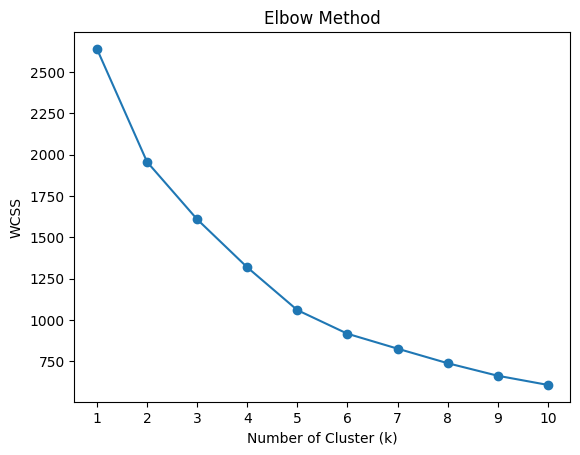

In [13]:
plt.plot(k_values,wcss,marker="o")
plt.xlabel("Number of Cluster (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.show()

In [14]:
optimal_k = 5

In [15]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)
df["Cluster"]= kmeans.fit_predict(X_scaled)

In [16]:
print("\nOpimal K =",optimal_k)

print("\nNumber of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nAverage purchasing behavior of each cluster :")
print(df.groupby("Cluster")[X.columns].mean().round(2))


Opimal K = 5

Number of customers in each cluster:
Cluster
0    270
1     10
2     63
3     96
4      1
Name: count, dtype: int64

Average purchasing behavior of each cluster :
            Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
Cluster                                                                      
0         9092.16   2967.76   3807.41   2271.76            989.81      978.96
1        15964.90  34708.50  48536.90   3054.60          24875.20     2942.80
2        32957.98   4997.35   5884.76   8422.84            954.60     2462.97
3         5754.17  10866.60  16607.10   1464.12           7202.88     1813.39
4        36847.00  43950.00  20170.00  36534.00            239.00    47943.00


ASSIGNMENT NO 7

K = 2 Silhouette Score = 0.2929
K = 3 Silhouette Score = 0.2191
K = 4 Silhouette Score = 0.0968
K = 5 Silhouette Score = 0.0611
K = 6 Silhouette Score = 0.0825
K = 7 Silhouette Score = 0.1039
K = 8 Silhouette Score = 0.1013
K = 9 Silhouette Score = 0.1009
K = 10 Silhouette Score = 0.0897


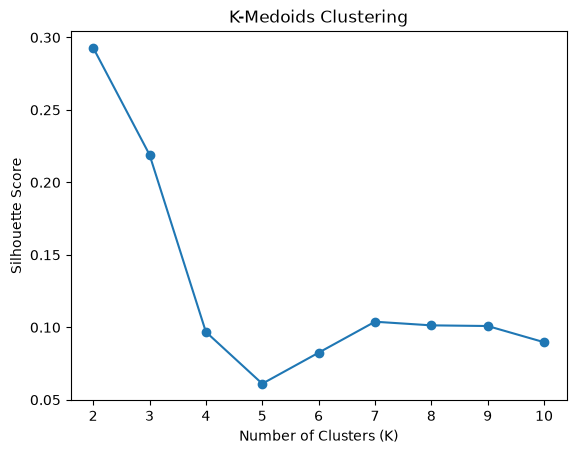


Optimal K: 2

Number of Customers in Each Cluster:
Cluster
0    171
1    269
Name: count, dtype: int64

Average Spending of Each Cluster:
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0        11422.47  10762.11  15691.06  2153.23           6502.64     2285.27
1        12367.62   2639.54   3031.19  3655.94            579.58     1041.49


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score

# 1. Load dataset
df = pd.read_csv("Wholesale customers data.csv")

# 2. Select purchasing features
X = df[["Fresh", "Milk", "Grocery", "Frozen",
        "Detergents_Paper", "Delicassen"]]

# 3. Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Find optimal K using Silhouette Score
scores = []

for k in range(2, 11):
    model = KMedoids(n_clusters=k, random_state=42)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    scores.append(score)

    print("K =", k, "Silhouette Score =", round(score, 4))

# 5. Plot Silhouette Score
plt.plot(range(2, 11), scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Medoids Clustering")
plt.xticks(range(2, 11))
plt.show()

# 6. Select optimal K
optimal_k = range(2, 11)[scores.index(max(scores))]

# 7. Apply K-Medoids
kmedoids = KMedoids(n_clusters=optimal_k, random_state=42)
df["Cluster"] = kmedoids.fit_predict(X_scaled)

# 8. Display results
print("\nOptimal K:", optimal_k)

print("\nNumber of Customers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nAverage Spending of Each Cluster:")
print(df.groupby("Cluster")[X.columns].mean().round(2))


ASSIGNMENT NO 8


 Linear Regression
MSE : 0.4759
MAE : 0.5464
RMSE: 0.6899
R2  : 0.3342

 Gradient Boosting
MSE : 0.4133
MAE : 0.511
RMSE: 0.6429
R2  : 0.4219


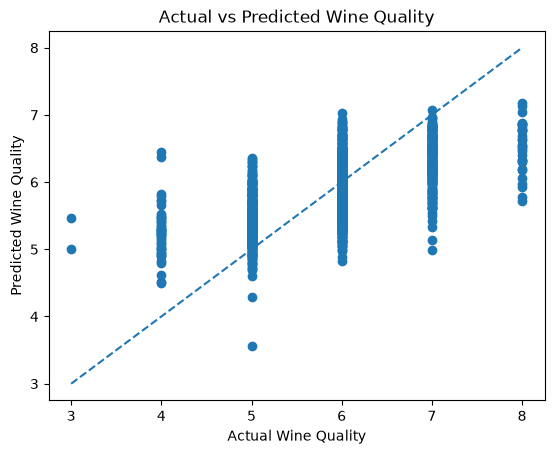

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load dataset
df = pd.read_csv("winequality.csv")

# Features and target
X = df.drop(["quality", "type"], axis=1)
y = df["quality"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Linear Regression Model
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# Gradient Boosting Model
gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

# Evaluation
for name, pred in [("Linear Regression", lr_pred),
                   ("Gradient Boosting", gb_pred)]:
    mse = mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    print("\n", name)
    print("MSE :", round(mse, 4))
    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2  :", round(r2, 4))

# Actual vs Predicted Plot
plt.scatter(y_test, gb_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], "--")

plt.xlabel("Actual Wine Quality")
plt.ylabel("Predicted Wine Quality")
plt.title("Actual vs Predicted Wine Quality")
plt.show()

ASSIGNMEENT NO 9

Accuracy: 0.7955
AUC-ROC: 0.8358
F1 Score: 0.5556

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.82      0.87       794
           1       0.47      0.68      0.56       184

    accuracy                           0.80       978
   macro avg       0.69      0.75      0.71       978
weighted avg       0.83      0.80      0.81       978



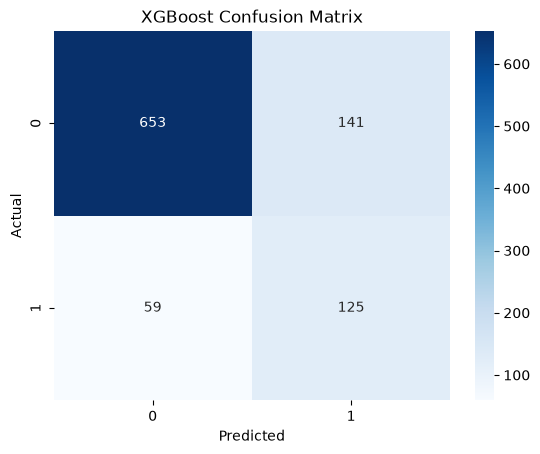

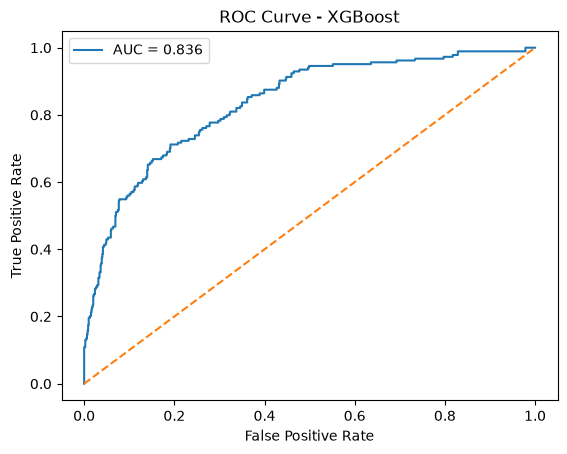

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, classification_report, roc_curve
)

from xgboost import XGBClassifier

# Load dataset
df = pd.read_csv("Travel.csv")

# Features and target
df = df.dropna(subset=["ProdTaken"])

X = df.drop(["ProdTaken", "CustomerID"], axis=1)
y = df["ProdTaken"].astype(int)

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

# Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Handle class imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# XGBoost Model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("AUC-ROC:", round(roc_auc_score(y_test, y_prob), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label="AUC = {:.3f}".format(
    roc_auc_score(y_test, y_prob)
))
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.show()

ASSIGNMENT NO 10

In [8]:
import gymnasium as gym
import numpy as np

# Create Taxi environment
env = gym.make("Taxi-v4", render_mode="ansi")

# Initialize Q-table
Q = np.zeros((env.observation_space.n, env.action_space.n))

# Q-learning parameters
alpha = 0.1
gamma = 0.9
epsilon = 1.0
episodes = 5000

# Train the agent
for episode in range(episodes):
    state, info = env.reset()
    done = False

    while not done:

        # Choose action
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(Q[state])

        # Take action
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # Update Q-table
        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) * (not done)
            - Q[state, action]
        )

        state = next_state

    # Reduce exploration
    epsilon = max(0.01, epsilon * 0.995)

print("Training completed!")

# Test the trained agent
state, info = env.reset()
done = False
total_reward = 0

print("\nTaxi Environment:")

while not done:

    # Select the best action
    action = np.argmax(Q[state])

    # Perform action
    state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated

    # Calculate total reward
    total_reward += reward

    # Display environment
    print(env.render())
    print("Reward:", reward)

print("Total Reward:", total_reward)

# Close environment
env.close()

Training completed!

Taxi Environment:
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (West)

Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (West)

Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Pickup)

Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
|_| : | : |
|Y| : |B: |
+---------+
  (North)

Reward: -1
+---------+
|R: | : :G|
| : | : : |
|_: : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

Reward: -1
+---------+
|R: | : :G|
| : | : : |
| :_: : : |
| | : | : |
|Y| : |B: |
+---------+
  (East)

Reward: -1
+--------

ASSIGNMENT NO 11

In [3]:
import random
import numpy as np

# Grid input
n = int(input("Enter grid size: "))
start = tuple(map(int, input("Enter start (row col): ").split()))
goal = tuple(map(int, input("Enter goal (row col): ").split()))

num_obstacles = int(input("Enter number of obstacles: "))
obstacles = [
    tuple(map(int, input("Enter obstacle (row col): ").split()))
    for _ in range(num_obstacles)
]

# Display grid
for i in range(n):
    print(" ".join(
        "S" if (i, j) == start else
        "G" if (i, j) == goal else
        "X" if (i, j) in obstacles else "."
        for j in range(n)
    ))

# Q-learning setup
Q = np.zeros((n * n, 4))
actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def state(p):
    return p[0] * n + p[1]

# Train agent
for ep in range(2000):
    p = start
    epsilon = max(0.01, 1 - ep / 2000)

    for _ in range(n * n * 4):
        s = state(p)

        if random.random() < epsilon:
            a = random.randrange(4)
        else:
            a = np.argmax(Q[s])

        r = p[0] + actions[a][0]
        c = p[1] + actions[a][1]

        nxt = (max(0, min(n - 1, r)),
               max(0, min(n - 1, c)))

        if nxt in obstacles:
            reward = -10
            nxt = p
        elif nxt == goal:
            reward = 100
        else:
            reward = -1

        ns = state(nxt)

        Q[s, a] += 0.7 * (
            reward + 0.95 * np.max(Q[ns]) * (nxt != goal)
            - Q[s, a]
        )

        p = nxt

        if p == goal:
            break

print("Training complete!")

# Find path
p = start
path = [start]

for _ in range(n * n):
    if p == goal:
        break

    a = np.argmax(Q[state(p)])
    r = p[0] + actions[a][0]
    c = p[1] + actions[a][1]

    nxt = (max(0, min(n - 1, r)),
           max(0, min(n - 1, c)))

    if nxt in obstacles or nxt == p:
        break

    p = nxt
    path.append(p)

print("Path:", path)
print("Goal reached:", p == goal)

Enter grid size:  5
Enter start (row col):  0 0
Enter goal (row col):  4 4
Enter number of obstacles:  4
Enter obstacle (row col):  1 1
Enter obstacle (row col):  1 3
Enter obstacle (row col):  2 3
Enter obstacle (row col):  3 1


S . . . .
. X . X .
. . . X .
. X . . .
. . . . G
Training complete!
Path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
Goal reached: True
